In [5]:
from ModelSimlink import RadiativeTransitions, Levels
from standard_imports import *
from loaders import index
from plots import adv_plt, splt, interactive
from scipy.optimize import curve_fit
from Tools import LinesManipulator

In [6]:
data = index.load_index_and_data( "TestData/RfPen/20230620" ) + index.load_index_and_data( "TestData/PlasmaBIC/20241031" )
# data = [ data[12] ]

Avantes spectrum TestData/RfPen/20230620\New Experiment0005.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0006.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0007.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0008.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0013.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0014.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0015.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0016.Raw8 normalized by a factor of 0.200000 s
8 rows loaded
Avantes spectrum TestData/PlasmaBIC/20241031\101_6us.RAW8 normalized by a factor of 0.400000 s
Avantes spectrum TestData/PlasmaBIC/20241031\102_6us.RAW8 normalized by a f

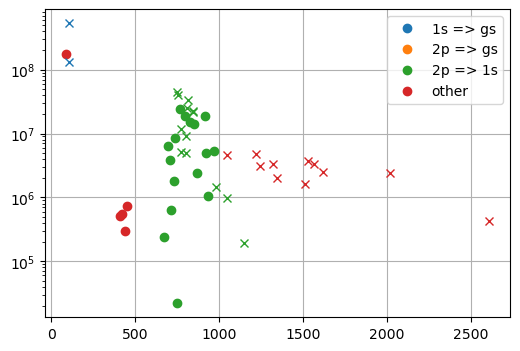

In [7]:
colors = adv_plt.list_colors()
lines_list = RadiativeTransitions.RadiativeTransitions().linesList()

for l in lines_list:
    if( l['from'].startswith('1s') and l['to'] == 'gs' ):
        l['color'] = colors[0]
    elif( l['from'].startswith('2p') and l['to'] == 'gs' ):
        l['color'] = colors[1]
    elif( l['from'].startswith('2p') and l['to'].startswith('1s') ):
        l['color'] = colors[2]
    else:
        l['color'] = colors[3]
    l['marker'] = 'o'

for i in range( len( lines_list ) - 2 ):
    if( lines_list[i+1]['wl'] - lines_list[i]['wl'] < 2 ):
        lines_list[i]['marker'] = 'x'
        lines_list[i+1]['marker'] = 'x'

for i in range( len( lines_list ) ):
    if( lines_list[i]['wl'] > 967 ):
        lines_list[i]['marker'] = 'x'

colors_legend = [ '1s => gs', '2p => gs', '2p => 1s', 'other']

splt.init()

for l in lines_list:
    plt.plot( l['wl'], l['A'], color=l['color'], marker = l['marker'] )
for col, leg in zip( colors, colors_legend ):
    plt.plot( [], [], 'o', color=col, label=leg )

plt.legend()
plt.yscale('log')

lines_selected = [ l for l in lines_list if l['marker'] == 'o' and l['color'] == colors[2] ]
wls_selected = [ l['wl'] for l in lines_selected ]

In [8]:
calib_base = pd.read_csv('CalibrationData/Calib_20250204_FCUVIR600.csv', index_col = False).to_dict('list')

In [9]:
worker = LinesManipulator.LinesManipulator()

In [ ]:
for d in data:
        d['wl_realigned'] = worker.realign_wl( d['avantes']['wl'], d['avantes']['int'] )
        d['int_withoutbaseline'] = worker.remove_baseline( d['avantes']['int'] )
        d['cal'] = worker.estimate_calibration( d['wl_realigned'], d['int_withoutbaseline'], calib_base, all_lines = RadiativeTransitions.RadiativeTransitions().linesList() )
        d['int_calibrated'] = d['cal']['int_calib']

Realigned with y = 1.00x + -0.16
Realigned with y = 1.00x + -0.15
Realigned with y = 1.00x + -0.16
Realigned with y = 1.00x + -0.13
Realigned with y = 1.00x + -0.14
Realigned with y = 1.00x + -0.13
Realigned with y = 1.00x + -0.13
Realigned with y = 1.00x + -0.12
Realigned with y = 1.00x + 0.51
Realigned with y = 1.00x + 0.54
Realigned with y = 1.00x + 0.55
Realigned with y = 1.00x + 0.45
Realigned with y = 1.00x + 0.49
Realigned with y = 1.00x + 0.53
Realigned with y = 1.00x + 0.52
Realigned with y = 1.00x + 0.52
Realigned with y = 1.00x + 0.52
Realigned with y = 1.00x + 0.51
Realigned with y = 1.00x + 0.34
Realigned with y = 1.00x + 0.35


In [13]:
lv = Levels.Levels()

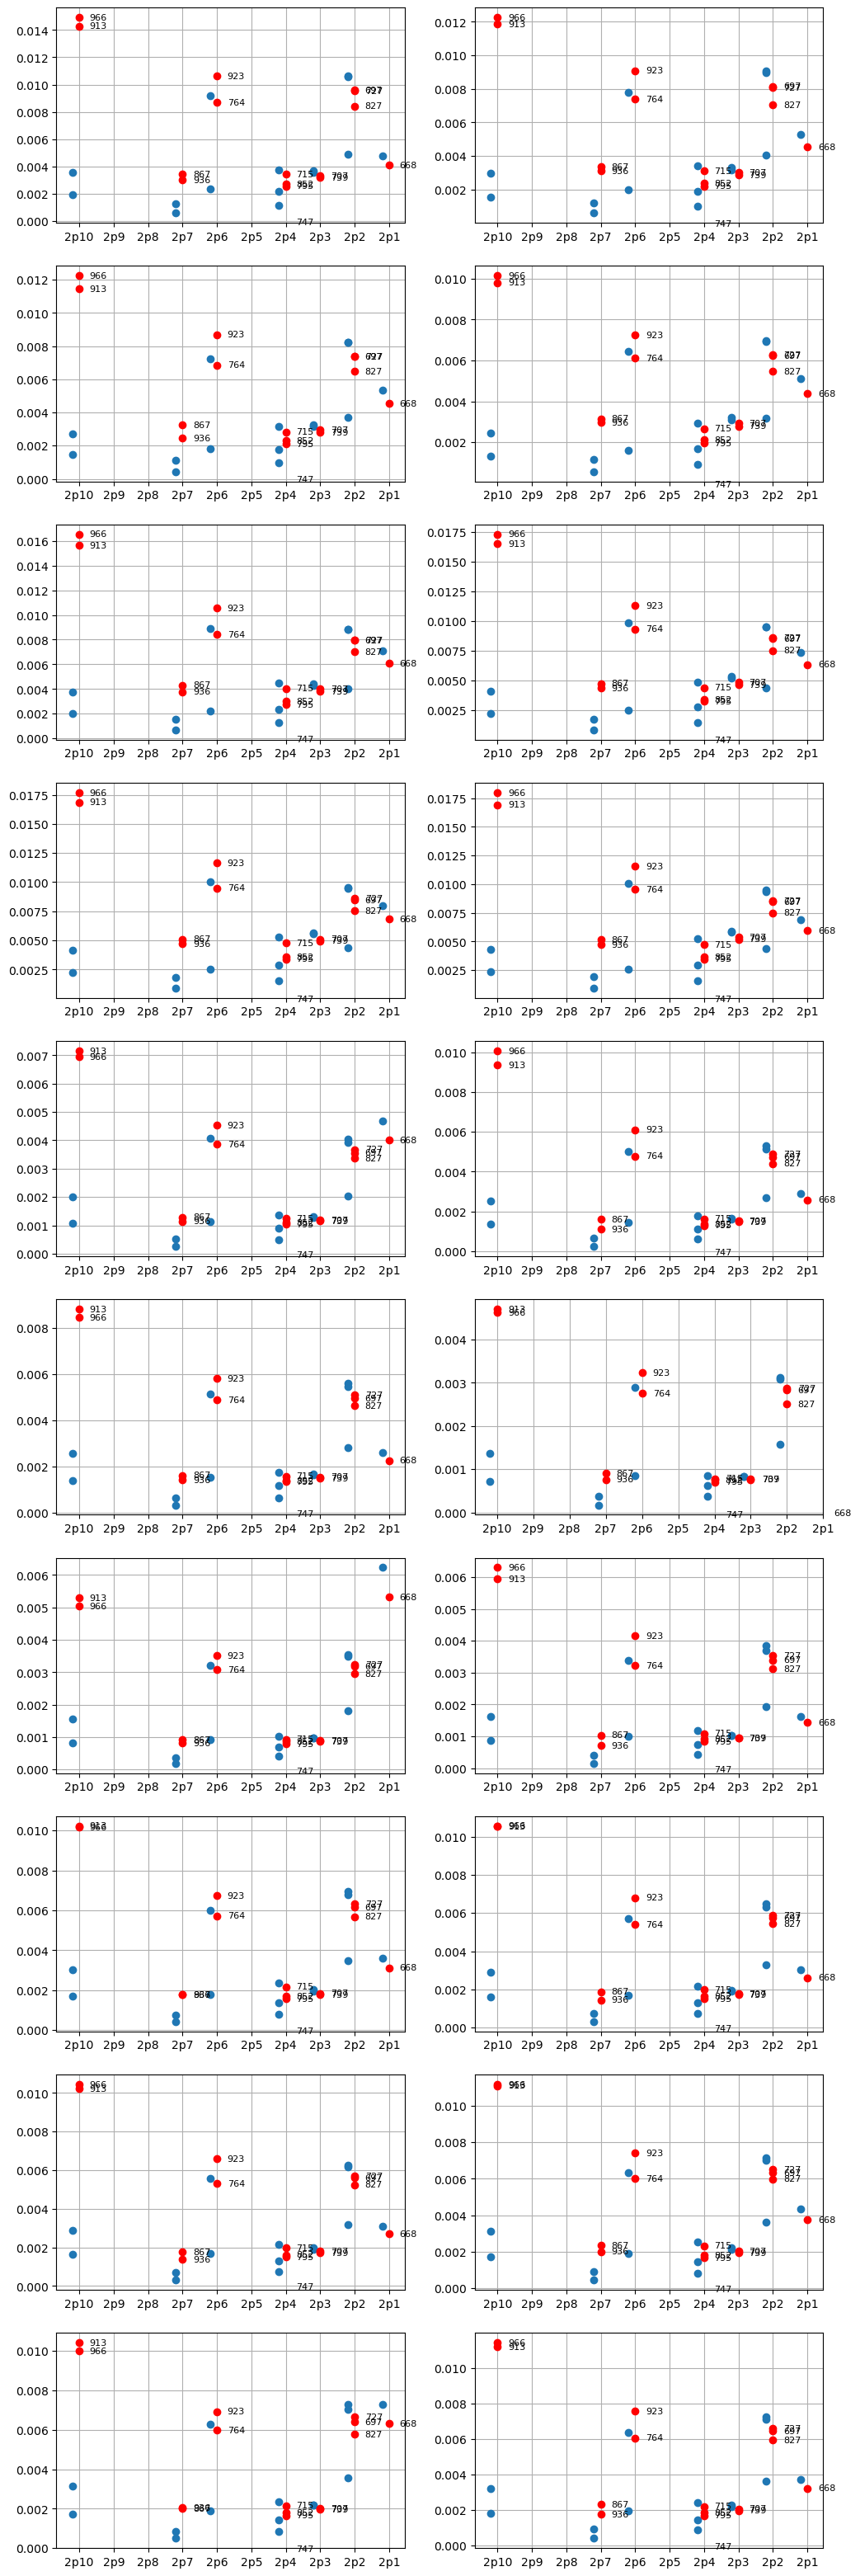

In [ ]:
splt.init_bytot( len( data ), cols = 2 )
for d in data:
    # Interp line by line
    d['uncal_densities'] = [
        worker.estimate_amplitude( d['wl_realigned'] - l['wl'], d['int_withoutbaseline'] ) / l['A'] for l in lines_selected
    ]
    d['cal_densities'] = [
        worker.estimate_amplitude( d['wl_realigned'] - l['wl'], d['int_calibrated'] ) / l['A'] for l in lines_selected
    ]

    splt.next()
    plt.plot(
        [ lv.ID( l['from'] ) - 0.2 for l, i in zip( lines_selected, d['uncal_densities'] ) if i > 0 ],
        [ i for i in d['uncal_densities'] if i > 0],
        'o'
    )

    plt.plot(
        [ lv.ID( l['from'] ) for l, i in zip( lines_selected, d['cal_densities'] ) if i > 0 ],
        [ i for i in d['cal_densities'] if i > 0 ],
        'ro'
    )


    for l, i in zip( lines_selected, d['cal_densities'] ):
        plt.text(
            lv.ID( l['from'] ) + 0.3,
            i,
            f"{l['wl']:.0f}",
            va = 'center',
            fontsize = 8
        )

    plt.xticks( np.arange( 5, 15 ), [ lv.name( i ) for i in range( 5,15 ) ])